<a href="https://colab.research.google.com/github/tettehdaniel/python-labs/blob/main/Notebooks/Notebook13_StatInference1_SV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 13 — (Introduction to) Statistical Inference One

**Main Objective**

1. Descriptive Statistics
2. One-Sample t-Test

## Setup

Please run the setup code below

In [1]:
! wget -q -nc https://raw.githubusercontent.com/taylor-arnold/fds-py/refs/heads/main/funs.py

from funs import *

In [2]:
import numpy as np
import polars as pl

from plotnine import *
from polars import col as c
theme_set(theme_minimal())

path = "https://raw.githubusercontent.com/ajcollins16/DSST289_Fall2026_AJC/refs/heads/main/"

In [3]:
speed = pl.read_csv(path + "Data/inference_speed_sex_height.csv")

## Introduction to Statistical Inference -- Descriptives

Today we will be focusing on the assessment of simple descriptive statistics like those to measure central tendendancy (mean, median, mode, quantiles) and spread (variance, standard deviation, range). We will also preview our first statistical tests the one-sample t-test. All of these concepts at face value are simple, and implementing them in Python is also simple.

We will see two sets of questions. The first set we are going to work through together with a fun activity using dice. While set two will use the `speed` dataset which has only three columns: speed of the person, sex of the person, and the height of the person (I have no idea what speed means here TBH).

### Questions (Set One)

0. Prior to any coding let's set the scene for our activity. Everyone is going to have two dice in which you are to destinguishe between the two by color (everyone will have different colors). You are going to roll both die at the same time and then take the difference between those two die. So say you have a black and white die. You will roll both die at the same time and then subtract say the number on the white die from the number on the black die. Make sure you always subtract in the same order of your colors. You will roll your dice 20 times. Below create a dataframe (just fill in everything between the brackets) with those difference scores that you calculated.



In [4]:
dice = pl.DataFrame({
    "diff": [-3, 1, -5, 3, 0, 2, -1, 3, -4, -1]
})

1. Using the data that you created, create a two seperate plots: (1) a  histogram and (2) a bar plot.

/usr/local/lib/python3.13/dist-packages/plotnine/stats/stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 3'. Pick better value with 'binwidth'.


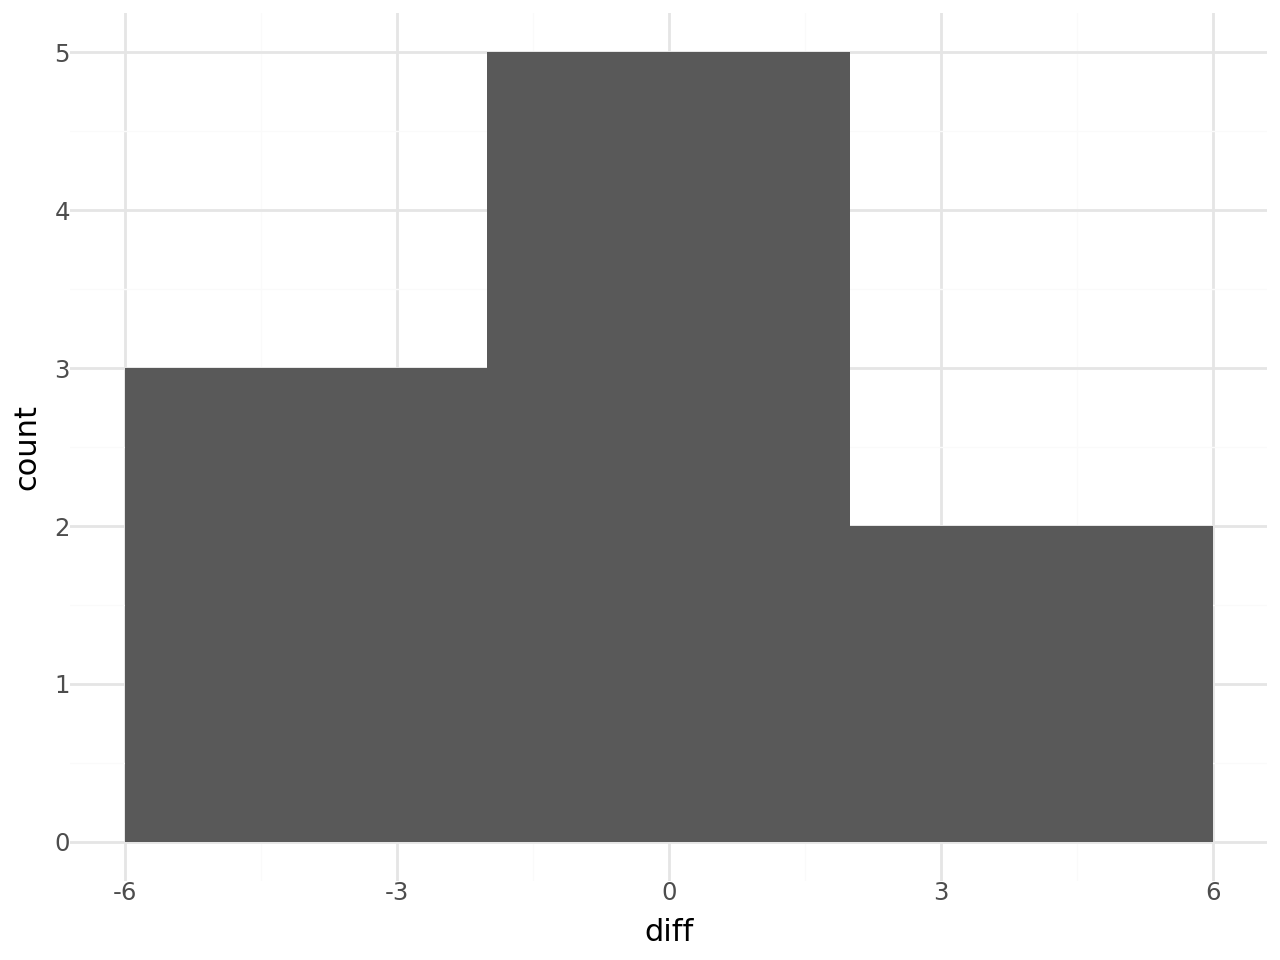

In [5]:
# Histogram Here
(
    dice
    .pipe(ggplot, aes("diff"))
    + geom_histogram()
)

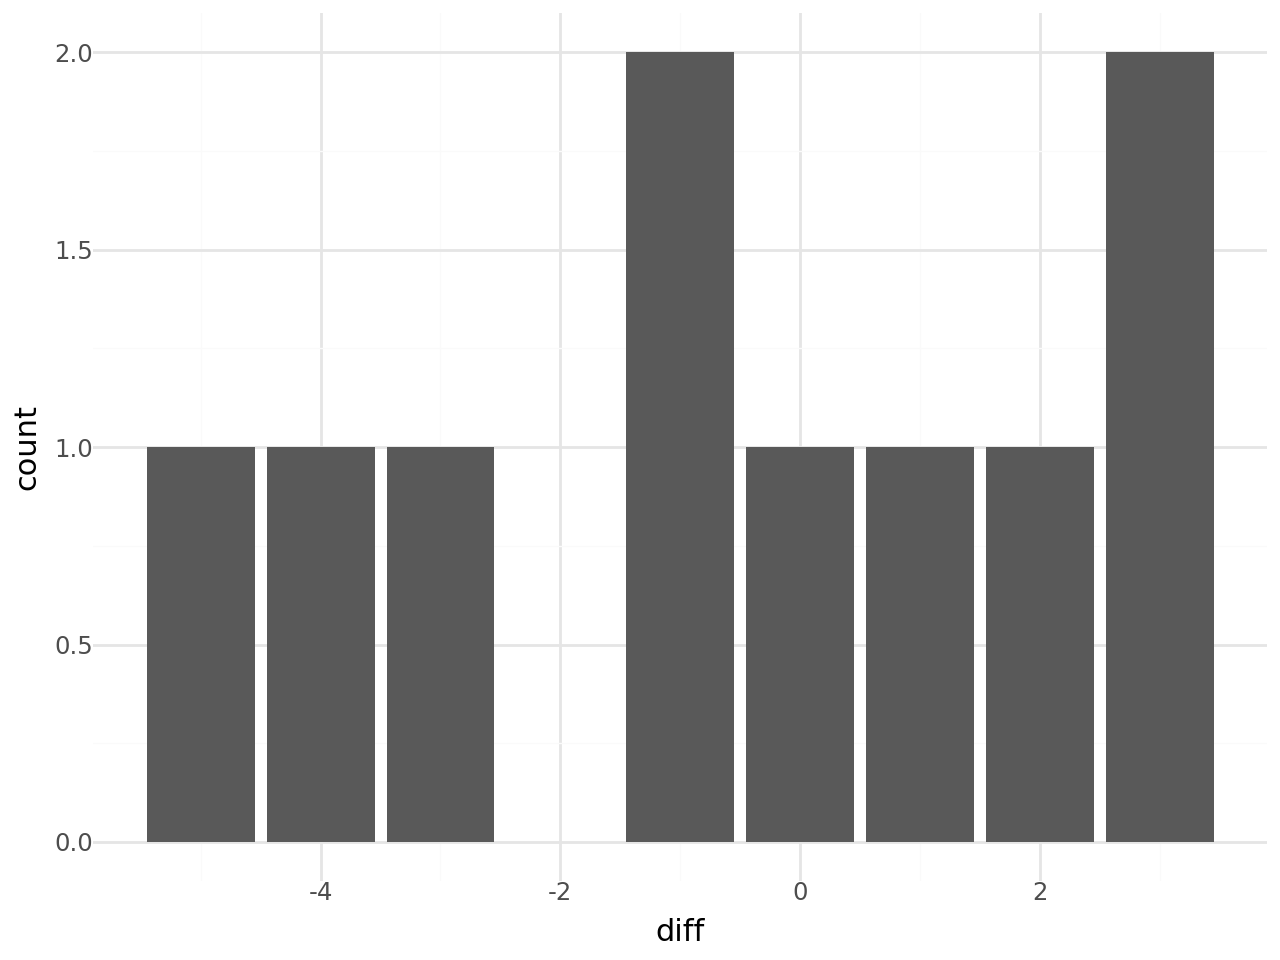

In [6]:
# Bar Plot Here
(
    dice
    .pipe(ggplot, aes("diff"))
    + geom_bar()
)

1. Which do you think is better, the histogram or bar plot, and why?

**Answer (Q1):** Bar plot, you see all the values better

2. Now compute the mean, median, and standard deviation for the `diff` scores you found.

In [7]:
(
    dice
    .select(
        mean = c.diff.mean(),
        med = c.diff.median(),
        std = c.diff.std()
    )
)

mean,med,std
f64,f64,f64
-0.5,-0.5,2.838231


2. When looking at the mean value how different do you think it is from 0? Think about this both from a literal sense as well as from a statistical sense.

**Answer (Q2):** It's pretty close to 0 in the literal sense. Statistically, it means that the more we roll the die the closer our mean value would ge to 0

3. Now we are going to run a one-sample t-test. Our goal of this test is to answer: Does rolling two fair six-sided dice and subtracting their value statistically show that it will be different from 0? Below are some important precurser questions before we run the statistical test:

- **First:** What would the *null hypothesis* ($H_0$) be? **Answer:**
There will be no statistical difference
- **Second:** What then would the *alternative hypothesis* ($H_1$) be? **Answer:**
There will be a statistical difference
- **Third:** What would a 95% confidence interval tell us about the mean difference score for our dice? **Answer:**
That it will happen in 95% of the times we repeat the experiment
- **Fourth:** Before running the one-sample t-test, what are we practically doing with the one-sample t-test for this example? What are we *infering* about? **Answer:**
We're looking to see how far our values are from zero.

4. Now, using the `DSStatsmodels.ttests1` wrapper function compute the 95%  confidence intervals around the difference score.

In [8]:
(
    dice
    .pipe(DSStatsmodels.ttest1, "diff ~ 1")
)

mean,t,P>|t|,[0.025,0.975]
f64,f64,f64,f64,f64
-0.5,-0.557086,0.591051,-2.530348,1.530348


4. Now let us interpret some things from this analysis.

- **First.** Our p-value is what? **Answer:** 0.59

- **Second.** How do you interpret this p-value? **Answer:** That our hypothesis is not statistically significant

- **Third.** Now, what is our 95% confidence interval? **Answer:** 1.55

- **Fourth:** Now would you interpret this 95% confidence interval (making sure to use the language from the data itself)? **Answer:** This measure is the upper limit of statistical insignificance. If we had recorded a mean higher than this value, it would be a significantly different result.

- **Fifth:** What then is our general conclusion about this difference score? **Answer:** It is insignificant.

### Questions (Set Two)

1. Now, using the `speed` dataset first I want you to calculate the mean, standard deviation, and sample size generally.

In [9]:
speed.head(5)

speed,sex,height
i64,str,f64
85,"""female""",69.0
40,"""male""",71.0
87,"""female""",64.0
110,"""female""",60.0
110,"""male""",70.0


In [10]:
(
    speed
    .select(
        mean = c.speed.mean(),
        count = pl.len(),
        std = c.speed.std()
    )
)

mean,count,std
f64,u32,f64
92.383112,1279,19.036006


2. Now provide the 95% confidence interval for the `speed` column of the `speed` dataset using the wrapper function we saw above.

In [11]:
(
    speed
    .pipe(DSStatsmodels.ttest1, "speed ~ 1")
)

mean,t,P>|t|,[0.025,0.975]
f64,f64,f64,f64,f64
92.383112,173.560949,0.0,91.338872,93.427351


3. Finally, using the formula seen in the textbook for calculating the 95% confidence interval and then compare it to the answer you got above in question 2 (where $t^{*} = 1.96$):

$95\% \text{ C.I.} = \bar{x} \pm t^{*} \times \frac{s}{\sqrt{n}}$

*Hint: copy what you have in question 1 above (of set 2) and add a `.with_columns()` to calculate the confidence interval. You will need to calculate both the upper and lower bound*

In [12]:
(
    speed
    .select(
        mean = c.speed.mean(),
        count = pl.len(),
        std = c.speed.std()
    )
    .with_columns(lower_bound = c.mean - 1.96 * (c.std/ c.count.sqrt()))
    .with_columns(upper_bound = c.mean + 1.96 * (c.std/ c.count.sqrt()))
)

mean,count,std,lower_bound,upper_bound
f64,u32,f64,f64,f64
92.383112,1279,19.036006,91.339842,93.426382


3. Are the statistical test confidence intervals and our confidence intervals the same or different?

**Answer (Q3):** Same